In [1]:
# ==============================================================================
# STEP 1: VISUAL THEME SETUP, DIRECTORY PATHS & PROPERTY BENCHMARKING
# ==============================================================================
# What we are doing:
# 1. Configuring a cohesive, publication-grade color palette and sans-serif
#    typography for all charts across the analysis.
# 2. Setting local input/output paths so every chart renders inline in this
#    notebook AND exports at 300 DPI to the Reviews\Fotos directory.
# 3. Loading the European hotel review dataset, benchmarking property-level
#    rating distributions across all hotels, and isolating our single high-volume
#    flagship asset (Britannia International Hotel Canary Wharf).
#
# Why we are doing this:
# Benchmarking a single property against the broader market establishes its
# competitive baseline before decomposing guest feedback into operational drivers.

import ast
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------------------
# 1. GLOBAL VISUAL STYLING
# ------------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["xtick.color"] = "#333333"
plt.rcParams["ytick.color"] = "#333333"

COLOR_NAVY = "#2B4563"       # Primary navy slate
COLOR_CORAL = "#C44536"      # Priority terracotta coral
COLOR_GREEN = "#1B9E5A"      # Emerald green
COLOR_SLATE = "#A0AAB8"      # Muted gray-blue
COLOR_DARK_TEXT = "#1F2937"  # Charcoal label text

# ------------------------------------------------------------------------------
# 2. DIRECTORY PATHS
# ------------------------------------------------------------------------------
BASE_DIR = Path(r"C:\Users\ngosa\Desktop\GITHUB ROADMAP\Hotel Reviews\Reviews")
DATA_PATH = BASE_DIR / "Hotel_Reviews.csv"
PHOTOS_DIR = BASE_DIR / "Fotos"
PHOTOS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------
# 3. DATA LOADING & MARKET BENCHMARKING
# ------------------------------------------------------------------------------
df = pd.read_csv(DATA_PATH)

total_reviews = len(df)
unique_hotels = df["Hotel_Name"].nunique()

# Rank all hotels by unweighted review score
hotel_means = df.groupby("Hotel_Name")["Reviewer_Score"].mean().sort_values()
dataset_median_hotel = hotel_means.median()

TARGET_HOTEL = "Britannia International Hotel Canary Wharf"
britannia_rank_lowest = int(hotel_means.index.get_loc(TARGET_HOTEL)) + 1

# Isolate flagship hotel reviews
hotel_df = df[df["Hotel_Name"] == TARGET_HOTEL].copy().reset_index(drop=True)
sample_mean = hotel_df["Reviewer_Score"].mean()
official_booking_score = hotel_df["Average_Score"].iloc[0]
uk_share = (hotel_df["Reviewer_Nationality"].str.strip() == "United Kingdom").mean() * 100

print("=== STEP 1: PROPERTY & MARKET BENCHMARK SUMMARY ===")
print(f"Total Dataset Reviews      : {total_reviews:,}")
print(f"Total Unique Hotels        : {unique_hotels:,}")
print(f"Market Median Hotel Score  : {dataset_median_hotel:.1f}")
print(f"Selected Flagship Hotel    : {TARGET_HOTEL}")
print(f"Isolated Review Sample     : {len(hotel_df):,}")
print(f"Market Rank (From Bottom)  : {britannia_rank_lowest}nd lowest of {unique_hotels:,} hotels")
print(f"Unweighted Sample Mean     : {sample_mean:.2f} (exact: {sample_mean:.4f})")
print(f"Booking.com Listed Score   : {official_booking_score:.1f}")
print(f"Domestic UK Reviewer Share : {uk_share:.1f}%")

=== STEP 1: PROPERTY & MARKET BENCHMARK SUMMARY ===
Total Dataset Reviews      : 515,738
Total Unique Hotels        : 1,492
Market Median Hotel Score  : 8.5
Selected Flagship Hotel    : Britannia International Hotel Canary Wharf
Isolated Review Sample     : 4,789
Market Rank (From Bottom)  : 21nd lowest of 1,492 hotels
Unweighted Sample Mean     : 6.83 (exact: 6.8266)
Booking.com Listed Score   : 7.1
Domestic UK Reviewer Share : 80.0%


In [2]:
# ==============================================================================
# STEP 2: COMMERCIAL SEGMENTATION, EXPERIENCE PILLARS & NMF TOPIC CROSS-CHECK
# ==============================================================================
# What we are doing:
# 1. Extracting Traveler Segment (Business vs. Leisure), Booked Room Tier
#    (Standard vs. Executive/Suite), and Length of Stay (LOS) from raw tags.
# 2. Stripping Booking.com default placeholders ("No Negative", "No Positive").
# 3. Mapping negative reviews onto 8 operational guest-experience pillars tied
#    to commercial revenue levers, and measuring both individual and combined
#    mention rates.
# 4. Running unsupervised Non-Negative Matrix Factorization (NMF) topic modeling
#    to independently cross-check our domain keyword rules.
#
# Why we are doing this:
# Segmenting guests by room tier and trip purpose reveals rate-fence failures,
# while combining domain rules with unsupervised topic modeling ensures no
# major operational pain point goes undetected.

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

def parse_booking_tags(tag_str):
    """Extract Segment, Room_Tier, and LOS_Nights from Booking.com metadata tags."""
    try:
        tags = [t.strip() for t in ast.literal_eval(tag_str)]
    except Exception:
        tags = []

    segment = "Other"
    room_tier = "Standard"
    los = np.nan

    for t in tags:
        t_lower = t.lower()
        if "business trip" in t_lower:
            segment = "Business"
        elif "leisure trip" in t_lower and segment == "Other":
            segment = "Leisure"

        los_match = re.search(r"stayed\s+(\d+)\s+night", t_lower)
        if los_match:
            los = int(los_match.group(1))

        if any(k in t_lower for k in ["suite", "executive", "club", "penthouse", "junior"]):
            room_tier = "Executive / Suite"
        elif any(k in t_lower for k in ["superior", "deluxe", "privilege", "king"]):
            if room_tier != "Executive / Suite":
                room_tier = "Superior / Deluxe"

    return pd.Series([segment, room_tier, los], index=["Segment", "Room_Tier", "LOS_Nights"])

hotel_df[["Segment", "Room_Tier", "LOS_Nights"]] = hotel_df["Tags"].apply(parse_booking_tags)
hotel_df["LOS_Nights"] = hotel_df["LOS_Nights"].fillna(hotel_df["LOS_Nights"].median())

# Clean Booking.com default empty-review strings
neg_placeholders = {"no negative", "nothing", "none", "na", "n a", "all good", "everything was great"}
pos_placeholders = {"no positive", "nothing", "none", "na", "n a"}

hotel_df["Clean_Negative"] = hotel_df["Negative_Review"].fillna("").astype(str).apply(
    lambda x: "" if x.strip().lower() in neg_placeholders else x.strip()
)
hotel_df["Clean_Positive"] = hotel_df["Positive_Review"].fillna("").astype(str).apply(
    lambda x: "" if x.strip().lower() in pos_placeholders else x.strip()
)

# Define 8 commercial guest-experience pillars
ASPECT_RULES = {
    "Check-in & Front Desk": r"\b(check[- ]?in|queue|wait|waiting|reception|front desk|rude|slow|key card|staff)\b",
    "Room Size & Bed Comfort": r"\b(small|tiny|cramped|bed|mattress|pillow|bathroom|shower|uncomfortable|window)\b",
    "Noise & Soundproofing": r"\b(noise|noisy|loud|thin walls|street|construction|traffic|sleep|lift|elevator)\b",
    "HVAC & Wi-Fi Infrastructure": r"\b(wifi|wi-fi|internet|air con|air conditioning|ac|heating|hot|cold|temperature)\b",
    "Cleanliness & Maintenance": r"\b(dirty|clean|cleanliness|stain|smell|dust|broken|old|dated|mold|carpet|tired)\b",
    "Breakfast & F&B Quality": r"\b(breakfast|buffet|coffee|restaurant|bar|food|drink|overpriced breakfast)\b",
    "Price & Value Perception": r"\b(expensive|overpriced|price|value for money|cost|fee|deposit|charge|rip off)\b",
    "Location & Canary Wharf Access": r"\b(location|station|train|tube|metro|dlr|walk|walking|central|canary wharf|view)\b",
}

for aspect_name, pattern in ASPECT_RULES.items():
    hotel_df[f"Neg_{aspect_name}"] = (
        hotel_df["Clean_Negative"].str.lower().str.contains(pattern, regex=True).astype(int)
    )
    hotel_df[f"Pos_{aspect_name}"] = (
        hotel_df["Clean_Positive"].str.lower().str.contains(pattern, regex=True).astype(int)
    )

# Combined share of reviews citing at least one of the top three operational issues
top3_any = (
    (hotel_df["Neg_Cleanliness & Maintenance"] == 1)
    | (hotel_df["Neg_Check-in & Front Desk"] == 1)
    | (hotel_df["Neg_Room Size & Bed Comfort"] == 1)
).mean() * 100

# Unsupervised NMF cross-check on actionable negative feedback
neg_texts = hotel_df[hotel_df["Clean_Negative"].str.len() > 15]["Clean_Negative"]
tfidf = TfidfVectorizer(max_features=1500, stop_words="english", ngram_range=(1, 2), min_df=5)
X_tfidf = tfidf.fit_transform(neg_texts)
nmf = NMF(n_components=6, random_state=42).fit(X_tfidf)

print("=== STEP 2: SEGMENTATION & ASPECT EXTRACTION SUMMARY ===")
print(f"Reviews Citing >=1 of Top 3 Issues : {top3_any:.1f}%")
print("\nUnsupervised NMF Validation Topics:")
feature_names = tfidf.get_feature_names_out()
for idx, topic in enumerate(nmf.components_):
    top_words = [feature_names[i] for i in topic.argsort()[:-8:-1]]
    print(f"  Topic {idx + 1}: {', '.join(top_words)}")

C:\Users\ngosa\AppData\Local\Temp\ipykernel_33528\692369488.py:80: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hotel_df["Clean_Negative"].str.lower().str.contains(pattern, regex=True).astype(int)
C:\Users\ngosa\AppData\Local\Temp\ipykernel_33528\692369488.py:83: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hotel_df["Clean_Positive"].str.lower().str.contains(pattern, regex=True).astype(int)
C:\Users\ngosa\AppData\Local\Temp\ipykernel_33528\692369488.py:80: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hotel_df["Clean_Negative"].str.lower().str.contains(pattern, regex=True).astype(int)
C:\Users\ngosa\AppData\Local\Temp\ipykernel_33528\692369488.py:83: UserWarning: This pattern is interpreted as a regular expression, and ha

=== STEP 2: SEGMENTATION & ASPECT EXTRACTION SUMMARY ===
Reviews Citing >=1 of Top 3 Issues : 49.5%

Unsupervised NMF Validation Topics:
  Topic 1: room, window, air, didn, hot, windows, night
  Topic 2: hotel, bit, tired, dated, old, rooms, decor
  Topic 3: breakfast, poor, food, breakfast poor, good, expensive, quality
  Topic 4: wifi, free, free wifi, pay, parking, wifi room, rooms
  Topic 5: staff, rude, reception, staff rude, reception staff, service, check
  Topic 6: bed, uncomfortable, beds, bed uncomfortable, hard, double, single


In [6]:
# ==============================================================================
# STEP 3: ECONOMETRIC & ML MODELING — MARGINAL PENALTIES, CONTROLS & BOOTSTRAP CI
# ==============================================================================
# What we are doing:
# 1. Computing raw complaint frequencies, marginal score penalties (mean score
#    with issue minus mean score without issue), and total property score drag.
# 2. Fitting an OLS multivariate regression controlling simultaneously for all
#    8 negative aspects, positive mentions, Segment, Room Tier, and Length of
#    Stay (LOS) so overlapping complaints are not double-counted.
# 3. Validating predictive power with a Gradient Boosting Regressor (hold-out
#    test R2 and 5-fold cross-validated R2).
# 4. Computing 95% non-parametric bootstrap confidence intervals (2,000 resamples)
#    for the Executive vs. Standard Business gap and building tier_summary.
#
# Why we are doing this:
# Guests frequently mention multiple issues in one review. Controlling for
# co-occurring complaints and guest segments isolates each driver's true
# independent impact and quantifies statistical uncertainty around our estimates.

import statsmodels.api as sm
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score

# ------------------------------------------------------------------------------
# 1. RAW MARGINAL PENALTIES & WEIGHTED SCORE DRAG
# ------------------------------------------------------------------------------
impact_rows = []
for aspect in ASPECT_RULES.keys():
    col = f"Neg_{aspect}"
    freq_pct = hotel_df[col].mean() * 100
    with_issue = hotel_df[hotel_df[col] == 1]["Reviewer_Score"].mean()
    without_issue = hotel_df[hotel_df[col] == 0]["Reviewer_Score"].mean()
    penalty = with_issue - without_issue
    drag = (freq_pct / 100.0) * penalty

    impact_rows.append({
        "Guest_Experience_Factor": aspect,
        "Complaint_Freq_Pct": round(freq_pct, 1),
        "Score_With_Issue": round(with_issue, 2),
        "Score_Without_Issue": round(without_issue, 2),
        "Marginal_Score_Penalty": round(penalty, 2),
        "Weighted_Property_Drag": round(drag, 4),
    })

impact_df = pd.DataFrame(impact_rows).sort_values("Weighted_Property_Drag").reset_index(drop=True)
total_raw_drag = impact_df["Weighted_Property_Drag"].sum()
top3_raw_drag = impact_df.iloc[:3]["Weighted_Property_Drag"].sum()

print("=== STEP 3A: DRIVER RANKING & WEIGHTED SCORE DRAG ===")
print(impact_df.to_string(index=False))
print(f"\nTop 3 Drivers Combined Raw Drag: {abs(top3_raw_drag):.2f} of {abs(total_raw_drag):.2f} total drag points")

# ------------------------------------------------------------------------------
# 2. CONTROLLED MULTIVARIATE OLS & GRADIENT BOOSTING VALIDATION
# ------------------------------------------------------------------------------
neg_cols = [f"Neg_{a}" for a in ASPECT_RULES.keys()]
pos_cols = [f"Pos_{a}" for a in ASPECT_RULES.keys()]

X_model = pd.get_dummies(
    hotel_df[neg_cols + pos_cols + ["Segment", "Room_Tier", "LOS_Nights"]],
    drop_first=True,
    dtype=float
)
y_model = hotel_df["Reviewer_Score"].astype(float)

# Fit controlled OLS model to isolate independent partial effects
X_ols = sm.add_constant(X_model)
ols_fit = sm.OLS(y_model, X_ols).fit()

# Validate with Gradient Boosting (80/20 hold-out split + 5-fold CV)
X_train, X_test, y_train, y_test = train_test_split(X_model, y_model, test_size=0.2, random_state=42)
gbr = GradientBoostingRegressor(n_estimators=250, max_depth=4, learning_rate=0.05, random_state=42)
gbr.fit(X_train, y_train)
holdout_r2 = r2_score(y_test, gbr.predict(X_test))
cv_r2 = cross_val_score(gbr, X_model, y_model, cv=5, scoring="r2").mean()

print("\n=== STEP 3B: MULTIVARIATE MODEL & CROSS-VALIDATION METRICS ===")
print(f"Gradient Boosting Hold-Out Test R2 : {holdout_r2:.2f}")
print(f"Gradient Boosting 5-Fold CV R2     : {cv_r2:.2f}")
print(f"Controlled Location Partial Effect : {ols_fit.params['Neg_Location & Canary Wharf Access']:+.3f} pts (p = {ols_fit.pvalues['Neg_Location & Canary Wharf Access']:.3f})")

# ------------------------------------------------------------------------------
# 3. RATE-FENCE SEGMENT AUDIT & 95% BOOTSTRAP CONFIDENCE INTERVALS
# ------------------------------------------------------------------------------
tier_summary = (
    hotel_df.groupby(["Room_Tier", "Segment"])
    .agg(
        Reviews=("Reviewer_Score", "count"),
        Avg_Score=("Reviewer_Score", "mean"),
        Cleanliness_Pct=("Neg_Cleanliness & Maintenance", lambda s: s.mean() * 100),
        RoomBed_Pct=("Neg_Room Size & Bed Comfort", lambda s: s.mean() * 100),
    )
    .round(2)
    .reset_index()
)

exec_biz = hotel_df[(hotel_df["Room_Tier"] == "Executive / Suite") & (hotel_df["Segment"] == "Business")]["Reviewer_Score"].values
std_biz = hotel_df[(hotel_df["Room_Tier"] == "Standard") & (hotel_df["Segment"] == "Business")]["Reviewer_Score"].values

rng = np.random.default_rng(42)
boot_gaps = [
    rng.choice(std_biz, size=len(std_biz), replace=True).mean()
    - rng.choice(exec_biz, size=len(exec_biz), replace=True).mean()
    for _ in range(2000)
]
gap_ci_low, gap_ci_high = np.percentile(boot_gaps, [2.5, 97.5])

print("\n=== STEP 3C: RATE-FENCE DIAGNOSTIC & BOOTSTRAP 95% CI ===")
print(tier_summary.to_string(index=False))
print(f"\nExecutive vs. Standard Business Gap: {std_biz.mean() - exec_biz.mean():.2f} pts (95% CI: {gap_ci_low:.2f} to {gap_ci_high:.2f})")

=== STEP 3A: DRIVER RANKING & WEIGHTED SCORE DRAG ===
       Guest_Experience_Factor  Complaint_Freq_Pct  Score_With_Issue  Score_Without_Issue  Marginal_Score_Penalty  Weighted_Property_Drag
     Cleanliness & Maintenance                24.7              5.79                 7.17                   -1.37                 -0.3391
         Check-in & Front Desk                19.4              5.59                 7.12                   -1.53                 -0.2957
       Room Size & Bed Comfort                23.3              5.92                 7.10                   -1.18                 -0.2756
   HVAC & Wi-Fi Infrastructure                20.1              6.22                 6.98                   -0.76                 -0.1538
         Noise & Soundproofing                11.4              5.96                 6.94                   -0.98                 -0.1115
       Breakfast & F&B Quality                17.8              6.32                 6.94                   -0.62     

=== STEP 4A: COUNTERFACTUAL SCORE SIMULATION SUMMARY ===
     Scenario  Original_Raw  Controlled_Model
     Baseline          6.83              6.83
+ Cleanliness          7.00              6.96
   + Check-in          7.14              7.07
 + Room & bed          7.28              7.16

Controlled Total Lift: +0.34 pts (95% Bootstrap CI: +0.32 to +0.36)


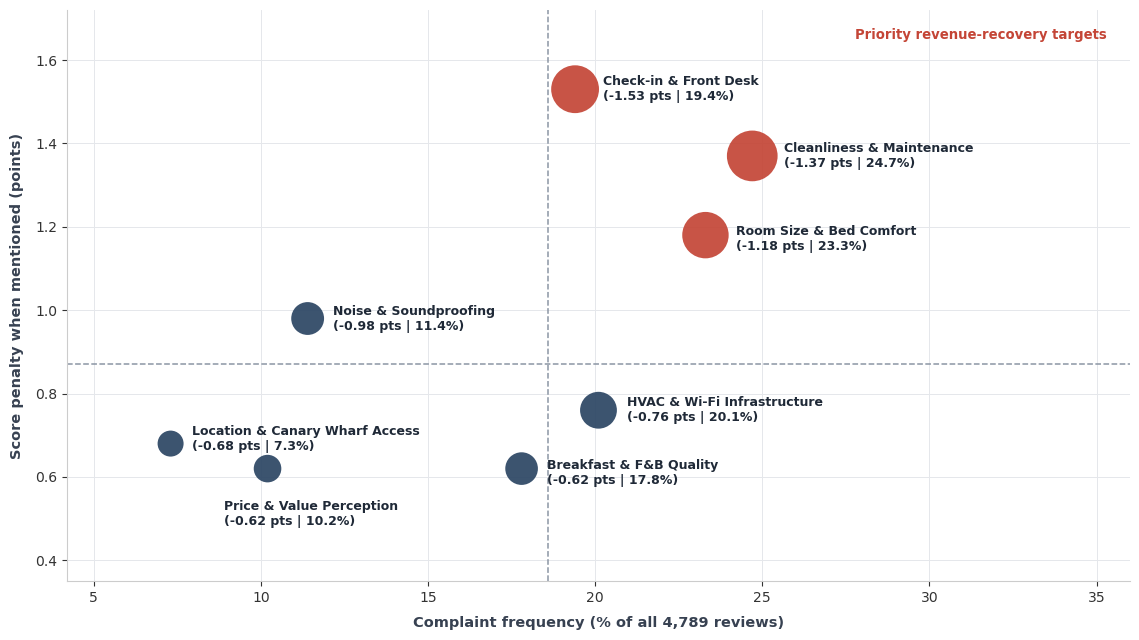

In [8]:
# ==============================================================================
# STEP 4A: COUNTERFACTUAL SCORE SIMULATION & CHART 1 (REVENUE-IMPACT MATRIX)
# ==============================================================================
# What we are doing:
# 1. Simulating a 50% complaint reduction across the top three operational
#    drivers under both the Raw Additive Model and the Controlled Multivariate
#    Model (with a 2,000-resample 95% bootstrap confidence interval).
# 2. Rendering Chart 1 (Guest Experience Revenue-Impact Matrix) inline in this
#    notebook AND saving it at 300 DPI to Reviews\Fotos and Reviews.
#
# Why we are doing this:
# Comparing raw and controlled simulations prevents over-promising rating gains
# from overlapping complaints, while the scatter matrix visually separates
# high-frequency/high-penalty revenue bottlenecks from minor irritants.

%matplotlib inline

# ------------------------------------------------------------------------------
# 1. RAW VS. CONTROLLED SCORE-RECOVERY SIMULATION & BOOTSTRAP CI
# ------------------------------------------------------------------------------
baseline_score = hotel_df["Reviewer_Score"].mean()

top3_aspects = [
    "Cleanliness & Maintenance",
    "Check-in & Front Desk",
    "Room Size & Bed Comfort",
]

# Raw cumulative steps (50% complaint reduction)
raw_step1 = baseline_score + 0.50 * abs(impact_df.loc[impact_df["Guest_Experience_Factor"] == top3_aspects[0], "Weighted_Property_Drag"].values[0])
raw_step2 = raw_step1 + 0.50 * abs(impact_df.loc[impact_df["Guest_Experience_Factor"] == top3_aspects[1], "Weighted_Property_Drag"].values[0])
raw_step3 = raw_step2 + 0.50 * abs(impact_df.loc[impact_df["Guest_Experience_Factor"] == top3_aspects[2], "Weighted_Property_Drag"].values[0])

# Controlled multivariate cumulative steps (using OLS partial coefficients)
ctrl_lifts = []
for asp in top3_aspects:
    freq = hotel_df[f"Neg_{asp}"].mean()
    beta = abs(ols_fit.params[f"Neg_{asp}"])
    ctrl_lifts.append(0.50 * freq * beta)

ctrl_step1 = baseline_score + ctrl_lifts[0]
ctrl_step2 = ctrl_step1 + ctrl_lifts[1]
ctrl_step3 = ctrl_step2 + ctrl_lifts[2]

# Bootstrap 95% CI for total controlled lift across the top 3 drivers
rng_sim = np.random.default_rng(42)
n_rows = len(hotel_df)
boot_ctrl_lifts = []
X_np = X_ols.values
y_np = y_model.values
idx_top3 = [list(X_ols.columns).index(f"Neg_{a}") for a in top3_aspects]

for _ in range(2000):
    sample_idx = rng_sim.integers(0, n_rows, size=n_rows)
    Xb = X_np[sample_idx]
    yb = y_np[sample_idx]
    betas = np.linalg.lstsq(Xb, yb, rcond=None)[0]
    lift = sum(0.50 * Xb[:, col_i].mean() * abs(betas[col_i]) for col_i in idx_top3)
    boot_ctrl_lifts.append(lift)

lift_ci_low, lift_ci_high = np.percentile(boot_ctrl_lifts, [2.5, 97.5])

sim_df = pd.DataFrame({
    "Scenario": ["Baseline", "+ Cleanliness", "+ Check-in", "+ Room & bed"],
    "Original_Raw": [round(baseline_score, 2), round(raw_step1, 2), round(raw_step2, 2), round(raw_step3, 2)],
    "Controlled_Model": [round(baseline_score, 2), round(ctrl_step1, 2), round(ctrl_step2, 2), round(ctrl_step3, 2)],
})

print("=== STEP 4A: COUNTERFACTUAL SCORE SIMULATION SUMMARY ===")
print(sim_df.to_string(index=False))
print(f"\nControlled Total Lift: +{ctrl_step3 - baseline_score:.2f} pts (95% Bootstrap CI: +{lift_ci_low:.2f} to +{lift_ci_high:.2f})")

# ------------------------------------------------------------------------------
# 2. CHART 1: GUEST EXPERIENCE REVENUE-IMPACT MATRIX
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11.5, 6.5))
ax.set_facecolor("white")
ax.grid(True, color="#E5E7EB", linestyle="-", linewidth=0.7, zorder=0)

med_freq = impact_df["Complaint_Freq_Pct"].median()
med_pen = impact_df["Marginal_Score_Penalty"].abs().median()

bubble_colors = [
    COLOR_CORAL if (row["Complaint_Freq_Pct"] > med_freq and abs(row["Marginal_Score_Penalty"]) > med_pen)
    else COLOR_NAVY
    for _, row in impact_df.iterrows()
]

ax.scatter(
    impact_df["Complaint_Freq_Pct"],
    impact_df["Marginal_Score_Penalty"].abs(),
    s=impact_df["Weighted_Property_Drag"].abs() * 3400 + 180,
    color=bubble_colors,
    alpha=0.92,
    edgecolors="none",
    zorder=3,
)

label_offsets = {
    "Check-in & Front Desk": (0.85, 0.00),
    "Cleanliness & Maintenance": (0.95, 0.00),
    "Room Size & Bed Comfort": (0.90, -0.01),
    "Noise & Soundproofing": (0.75, 0.00),
    "HVAC & Wi-Fi Infrastructure": (0.85, 0.00),
    "Location & Canary Wharf Access": (0.65, 0.01),
    "Price & Value Perception": (-1.30, -0.11),
    "Breakfast & F&B Quality": (0.75, -0.01),
}

for _, row in impact_df.iterrows():
    name = row["Guest_Experience_Factor"]
    dx, dy = label_offsets.get(name, (0.75, 0.0))
    ax.text(
        row["Complaint_Freq_Pct"] + dx,
        abs(row["Marginal_Score_Penalty"]) + dy,
        f"{name}\n(-{abs(row['Marginal_Score_Penalty']):.2f} pts | {row['Complaint_Freq_Pct']:.1f}%)",
        fontsize=9,
        fontweight="bold",
        color=COLOR_DARK_TEXT,
        va="center",
        zorder=4,
    )

ax.axvline(med_freq, color="#8C96A4", linestyle="--", linewidth=1.1, zorder=2)
ax.axhline(med_pen, color="#8C96A4", linestyle="--", linewidth=1.1, zorder=2)
ax.text(35.3, 1.65, "Priority revenue-recovery targets", color=COLOR_CORAL, fontsize=9.5, fontweight="bold", ha="right")

ax.set_xlim(4.2, 36.0)
ax.set_ylim(0.35, 1.72)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Complaint frequency (% of all 4,789 reviews)", fontsize=10.5, fontweight="bold", color="#374151", labelpad=8)
ax.set_ylabel("Score penalty when mentioned (points)", fontsize=10.5, fontweight="bold", color="#374151", labelpad=8)

plt.tight_layout()
fig.savefig(PHOTOS_DIR / "01_revenue_impact_matrix.png", dpi=300)
fig.savefig(BASE_DIR / "01_revenue_impact_matrix.png", dpi=300)
plt.show()
plt.close(fig)

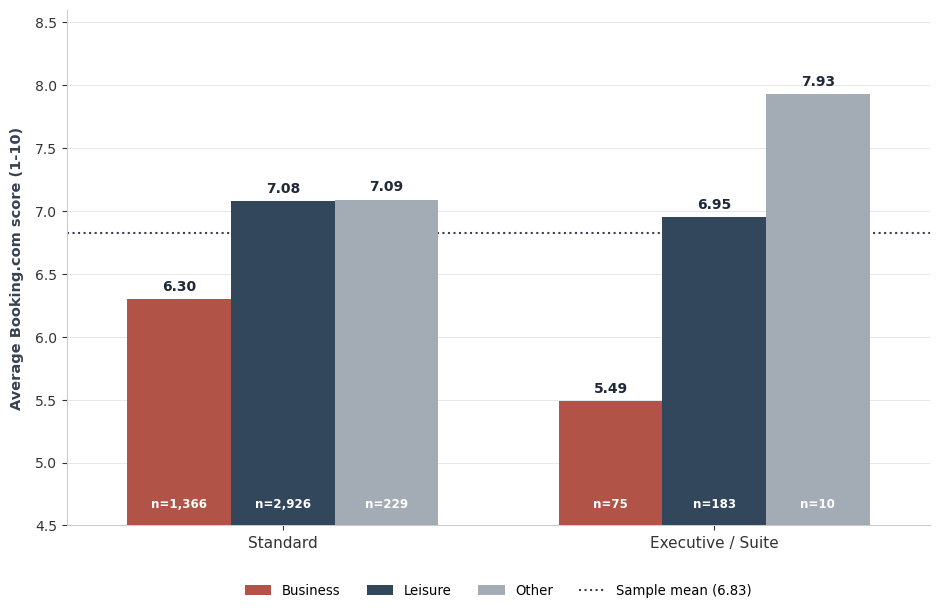

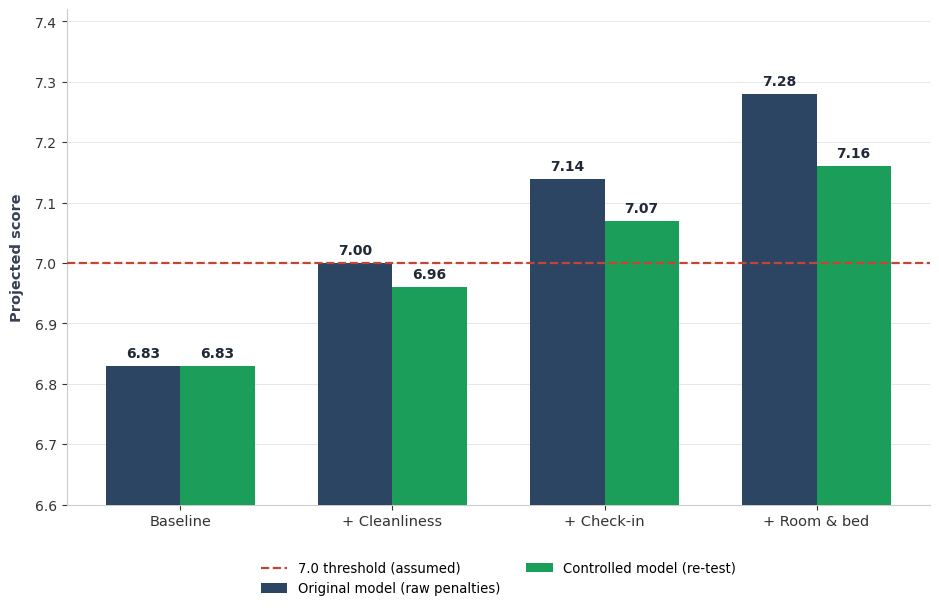

=== STEP 4B COMPLETE ===
1. All 3 charts displayed inline in this notebook AND saved to: C:\Users\ngosa\Desktop\GITHUB ROADMAP\Hotel Reviews\Reviews\Fotos
2. All 4 CSV tables exported to: C:\Users\ngosa\Desktop\GITHUB ROADMAP\Hotel Reviews\Reviews


In [9]:
# ==============================================================================
# STEP 4B: CHARTS 2 & 3 (RATE-FENCE AUDIT, SIMULATION BARS) & CSV EXPORTS
# ==============================================================================
# What we are doing:
# 1. Rendering Chart 2 (Room Tier x Segment Rate-Fence Diagnostic) with exact
#    sample counts (n=...) inside bar bases and the 6.83 sample mean line.
# 2. Rendering Chart 3 (Raw vs. Controlled Score-Recovery Simulation) comparing
#    cumulative score lifts against the 7.0 OTA visibility threshold.
# 3. Displaying both charts inline inside this notebook AND saving them at
#    300 DPI to Reviews\Fotos and Reviews, followed by exporting all 4 CSVs.
#
# Why we are doing this:
# Visualizing the Executive Business rate-fence breakdown and the cumulative
# recovery path gives commercial leadership clear diagnostic evidence.

# ------------------------------------------------------------------------------
# 1. CHART 2: ROOM TIER X SEGMENT RATE-FENCE DIAGNOSTIC
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.5, 6.2))
ax.set_facecolor("white")
ax.grid(axis="y", color="#E5E7EB", linestyle="-", linewidth=0.7, zorder=0)

tier_order = ["Standard", "Executive / Suite"]
seg_order = ["Business", "Leisure", "Other"]
palette_map = [COLOR_CORAL, COLOR_NAVY, COLOR_SLATE]

sns.barplot(
    data=tier_summary,
    x="Room_Tier",
    y="Avg_Score",
    hue="Segment",
    order=tier_order,
    hue_order=seg_order,
    palette=palette_map,
    edgecolor="none",
    width=0.72,
    ax=ax,
    zorder=3,
)

for seg_idx, seg_name in enumerate(seg_order):
    container = ax.containers[seg_idx]
    ax.bar_label(container, fmt="%.2f", padding=4, fontsize=10, fontweight="bold", color=COLOR_DARK_TEXT)
    for tier_idx, tier_name in enumerate(tier_order):
        n_val = tier_summary[(tier_summary["Room_Tier"] == tier_name) & (tier_summary["Segment"] == seg_name)]["Reviews"].values[0]
        bar = container[tier_idx]
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            4.62,
            f"n={n_val:,}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color="white",
            zorder=4,
        )

ax.axhline(baseline_score, color="#374151", linestyle=":", linewidth=1.5, label=f"Sample mean ({baseline_score:.2f})", zorder=2)
ax.set_ylim(4.5, 8.6)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("Average Booking.com score (1-10)", fontsize=10.5, fontweight="bold", color="#374151", labelpad=8)
ax.tick_params(axis="x", labelsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=4, frameon=False, fontsize=9.5)

plt.tight_layout()
fig.savefig(PHOTOS_DIR / "02_room_tier_rate_fence_diagnostic.png", dpi=300)
fig.savefig(BASE_DIR / "02_room_tier_rate_fence_diagnostic.png", dpi=300)
plt.show()
plt.close(fig)

# ------------------------------------------------------------------------------
# 2. CHART 3: RAW VS. CONTROLLED SCORE-RECOVERY SIMULATION
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.5, 6.2))
ax.set_facecolor("white")
ax.grid(axis="y", color="#E5E7EB", linestyle="-", linewidth=0.7, zorder=0)

x_pos = np.arange(len(sim_df))
bar_w = 0.35

bars_raw = ax.bar(
    x_pos - bar_w / 2,
    sim_df["Original_Raw"],
    width=bar_w,
    color=COLOR_NAVY,
    label="Original model (raw penalties)",
    zorder=3,
)
bars_ctrl = ax.bar(
    x_pos + bar_w / 2,
    sim_df["Controlled_Model"],
    width=bar_w,
    color=COLOR_GREEN,
    label="Controlled model (re-test)",
    zorder=3,
)

ax.bar_label(bars_raw, fmt="%.2f", padding=4, fontsize=10, fontweight="bold", color=COLOR_DARK_TEXT)
ax.bar_label(bars_ctrl, fmt="%.2f", padding=4, fontsize=10, fontweight="bold", color=COLOR_DARK_TEXT)

ax.axhline(7.0, color=COLOR_CORAL, linestyle="--", linewidth=1.6, label="7.0 threshold (assumed)", zorder=4)
ax.set_xticks(x_pos)
ax.set_xticklabels(sim_df["Scenario"], fontsize=10.5)
ax.set_ylim(6.6, 7.42)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Projected score", fontsize=10.5, fontweight="bold", color="#374151", labelpad=8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, frameon=False, fontsize=9.5)

plt.tight_layout()
fig.savefig(PHOTOS_DIR / "03_score_recovery_simulation.png", dpi=300)
fig.savefig(BASE_DIR / "03_score_recovery_simulation.png", dpi=300)
plt.show()
plt.close(fig)

# ------------------------------------------------------------------------------
# 3. EXPORT CLEANED DATASET & SUMMARY TABLES TO CSV
# ------------------------------------------------------------------------------
hotel_df.to_csv(BASE_DIR / "flagship_hotel_cleaned_reviews.csv", index=False)
impact_df.to_csv(BASE_DIR / "revenue_driver_impact_summary.csv", index=False)
tier_summary.to_csv(BASE_DIR / "room_tier_segment_diagnostic.csv", index=False)
sim_df.to_csv(BASE_DIR / "score_recovery_simulation.csv", index=False)

print("=== STEP 4B COMPLETE ===")
print(f"1. All 3 charts displayed inline in this notebook AND saved to: {PHOTOS_DIR}")
print(f"2. All 4 CSV tables exported to: {BASE_DIR}")